# 01 · Exploración de datos y preprocesamiento
**Equipo 9 – Predicción de fallas en el sistema APS de camiones Scania**

## 1. Descripción del problema
El sistema **APS** (*Air Pressure System*) genera aire presurizado para funciones del camión como frenado y cambio de marchas. Scania publicó lecturas anónimas de sensores de camiones en operación. La variable `class` vale:

- `pos`: el camión tuvo una falla atribuible a un componente del **APS**.
- `neg`: la falla corresponde a **otro** componente.

El objetivo de negocio es **anticipar fallas del APS** para enviar el camión a mantenimiento preventivo. El reto original (IDA 2016) define un **costo asimétrico**:

| Error | Significado | Costo |
|---|---|---|
| Falso positivo (FP) | revisión innecesaria en taller | 10 |
| Falso negativo (FN) | falla APS no detectada (avería en ruta) | 500 |

$$\text{Costo total} = 10\cdot FP + 500\cdot FN$$

**Preguntas que guían este notebook**
1. ¿Cómo es la estructura del dataset (tamaño, tipos, balance de clases)?
2. ¿Cuántos datos faltan, siguen algún patrón y son informativos respecto a la falla?
3. ¿Cómo se distribuyen las variables? ¿Son asimétricas o redundantes?
4. ¿Qué estrategia de imputación y de selección de variables conviene, sin fuga de información?
5. ¿Las clases se separan en un espacio de baja dimensión (PCA, t-SNE)?

In [2]:
import sys, time, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import os

os.environ["PYTHONPATH"] = str(ROOT)  # para que los workers de joblib importen src/
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import load_aps, histogram_groups
from src.preprocessing import (
    build_preprocessor,
    DropHighMissing,
    CorrelationFilter,
    signed_log1p,
)

FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
SEED = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)


def savefig(name):
    plt.savefig(FIG / f"{name}.png", dpi=130, bbox_inches="tight")

## 2. Comprensión de los datos
Los CSV oficiales traen unas 20 líneas de licencia antes del encabezado. `load_aps` localiza el encabezado de forma automática y convierte `"na"` en `NaN`. El **test oficial** se carga solo para describir su balance. Todas las decisiones de preprocesamiento se toman con el conjunto de entrenamiento.

In [3]:
X, y = load_aps("train")
X_test, y_test = load_aps("test")
print(f"Train: {X.shape[0]:,} filas × {X.shape[1]} variables | Test: {X_test.shape[0]:,} filas")
print("Tipos:", X.dtypes.value_counts().to_dict())
X.iloc[:5, :12]

Train: 60,000 filas × 170 variables | Test: 16,000 filas
Tipos: {dtype('float64'): 170}


,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,ag_003,ag_004,ag_005
0,76698.0,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,0.0,37250.0,1432864.0
1,33058.0,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,0.0,18254.0,653294.0
2,41040.0,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,0.0,1648.0,370592.0
3,12.0,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,318.0,2212.0,3232.0
4,60874.0,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,0.0,43752.0,1966618.0


,train,test
target,,
neg,59000.00,15625.00
pos,1000.00,375.00
% pos,1.67,2.34


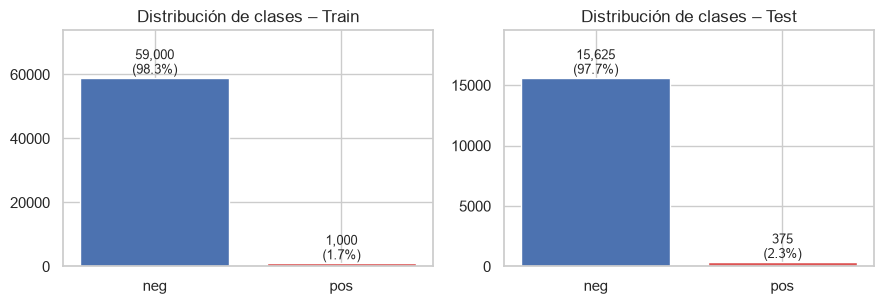

In [ ]:
balance = pd.DataFrame(
    {"train": y.value_counts(), "test": y_test.value_counts()}
).rename(index={0: "neg", 1: "pos"})
balance.loc["% pos"] = (balance.loc["pos"] / balance.sum() * 100).round(2)
display(balance)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, (name, s) in zip(axes, [("Train", y), ("Test", y_test)]):
    counts = s.map({0: "neg", 1: "pos"}).value_counts()
    ax.bar(counts.index, counts.values, color=["#4C72B0", "#DD5555"])
    for i, v in enumerate(counts.values):
        ax.text(
            i, v, f"{v:,}\n({v / len(s):.1%})", ha="center", va="bottom", fontsize=9
        )
    ax.set_title(f"Distribución de clases – {name}")
    ax.set_ylim(0, counts.max() * 1.25)
plt.tight_layout()
savefig("01_balance_clases")
plt.show()

**Desbalance:** solo el **1,67 %** de los registros de entrenamiento son fallas APS, es decir, 1 por cada 59 negativos. Un modelo que prediga siempre `neg` tendría una accuracy del 98,3 % y un costo de 1 000 × 500 = 500 000. Por eso la accuracy no sirve aquí y se usarán **Recall, Precision, F1, PR-AUC y el costo**.

Las 170 variables son numéricas y anónimas (`aa_000` … `eg_000`). Algunas comparten prefijo con bins `_000`–`_009`: son **histogramas** de una misma magnitud.

In [ ]:
groups = histogram_groups(X.columns)
hist_cols = [c for cols in groups.values() for c in cols]
print(
    f"{len(groups)} histogramas × 10 bins = {len(hist_cols)} variables:", list(groups)
)
print(f"Variables 'simples': {X.shape[1] - len(hist_cols)}")
desc = X.describe().T
desc["skew"] = X.skew()
desc["n_unique"] = X.nunique()
desc.sort_values("skew", ascending=False).head(10)

7 histogramas × 10 bins = 70 variables: ['ag', 'ay', 'az', 'ba', 'cn', 'cs', 'ee']
Variables 'simples': 100


,count,mean,std,min,25%,50%,75%,max,skew,n_unique
cs_009,59331.0,779.197755,1.843585e+05,0.0,0.0,0.0,0.0,4.490299e+07,243.531177,53
cf_000,45139.0,190221.810984,4.040441e+07,0.0,0.0,2.0,2.0,8.584298e+09,212.459407,525
co_000,45139.0,190515.566938,4.040441e+07,0.0,0.0,8.0,72.0,8.584298e+09,212.459406,1860
ad_000,45139.0,190620.639314,4.040441e+07,0.0,24.0,126.0,430.0,8.584298e+09,212.459406,1886
dh_000,55992.0,4707.073332,5.602799e+05,0.0,0.0,0.0,0.0,1.247009e+08,202.907014,1055
az_009,59329.0,42.073455,3.256570e+03,0.0,0.0,0.0,0.0,6.661480e+05,163.609146,336
ay_009,59329.0,1162.621618,9.796080e+04,0.0,0.0,0.0,0.0,1.882466e+07,159.066837,447
ag_000,59329.0,221.636367,2.047846e+04,0.0,0.0,0.0,0.0,3.376892e+06,153.387555,154
dj_000,55993.0,39.938564,4.533142e+03,0.0,0.0,0.0,0.0,7.267500e+05,150.507647,72
cs_007,59331.0,14771.417471,8.005122e+04,0.0,1204.0,6104.0,18164.0,1.288422e+07,140.732294,17300


In [6]:
print("Valor mínimo global:", X.min().min(), "| ¿hay negativos?", (X < 0).any().any())
print("Variables constantes:", desc.index[desc["n_unique"] <= 1].tolist())
print(f"Variables con |skew| > 5: {(desc['skew'].abs() > 5).sum()} de {len(desc)}")

Valor mínimo global: 0.0 | ¿hay negativos? False
Variables constantes: ['cd_000']
Variables con |skew| > 5: 157 de 170


## 3. Valores faltantes

Celdas faltantes: 8.33% del total
Filas con al menos un NaN: 99.0%
Variables por rango de faltantes:
0%            1
(0,5%]      127
(5,20%]      18
(20,50%]     16
(50,70%]      1
>70%          7
Name: count, dtype: int64


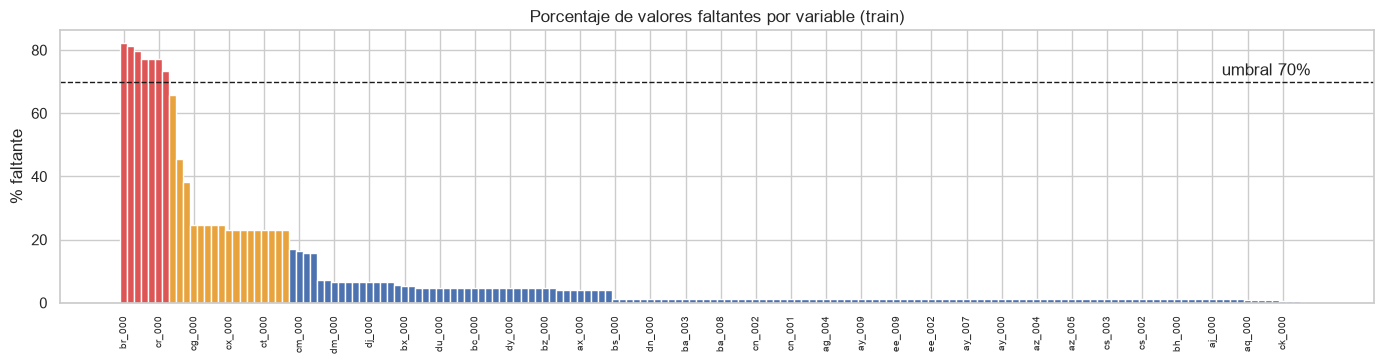

,% faltante
br_000,82.1%
bq_000,81.2%
bp_000,79.6%
bo_000,77.2%
ab_000,77.2%
cr_000,77.2%
bn_000,73.3%
bm_000,65.9%
bl_000,45.5%
bk_000,38.4%


In [ ]:
miss = X.isna().mean().sort_values(ascending=False)
print(f"Celdas faltantes: {X.isna().values.mean():.2%} del total")
print(f"Filas con al menos un NaN: {X.isna().any(axis=1).mean():.1%}")
print("Variables por rango de faltantes:")
print(
    pd.cut(
        miss,
        [-0.001, 0, 0.05, 0.2, 0.5, 0.7, 1.0],
        labels=["0%", "(0,5%]", "(5,20%]", "(20,50%]", "(50,70%]", ">70%"],
    )
    .value_counts()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(14, 3.8))
colors = np.where(miss > 0.7, "#DD5555", np.where(miss > 0.2, "#E8A33D", "#4C72B0"))
ax.bar(range(len(miss)), miss.values * 100, color=colors, width=1.0)
ax.axhline(70, ls="--", c="k", lw=1)
ax.text(len(miss) - 1, 72, "umbral 70%", ha="right")
ax.set_xticks(range(0, len(miss), 5))
ax.set_xticklabels(miss.index[::5], rotation=90, fontsize=7)
ax.set_ylabel("% faltante")
ax.set_title("Porcentaje de valores faltantes por variable (train)")
plt.tight_layout()
savefig("01_faltantes_por_variable")
plt.show()
miss.head(12).to_frame("% faltante").style.format("{:.1%}")

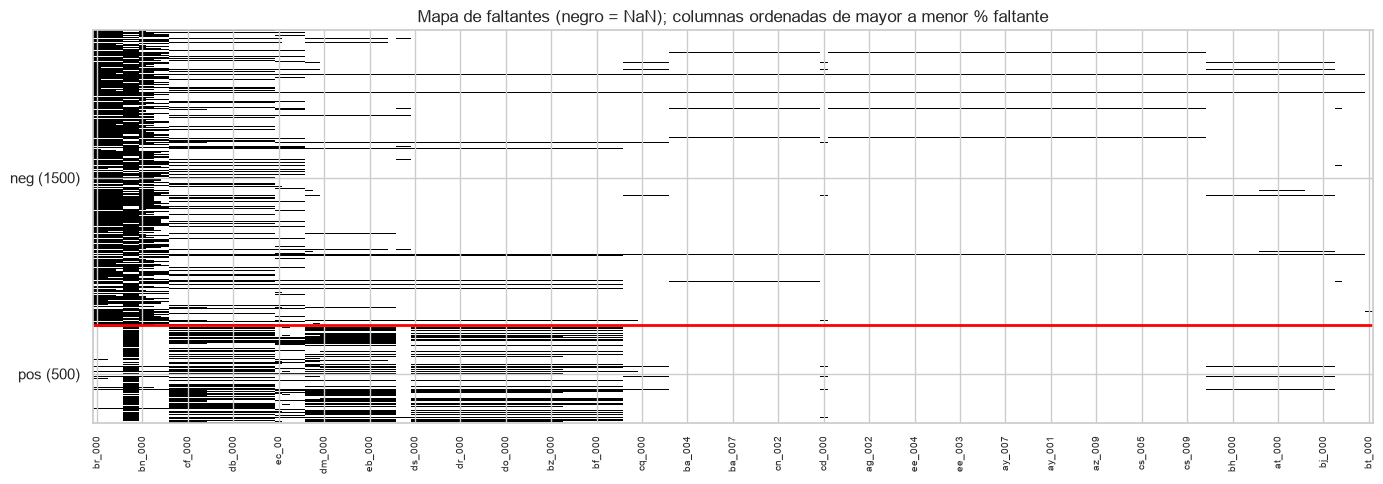

In [ ]:
# Patrón de faltantes: muestra estratificada, ordenada por clase
rng = np.random.default_rng(SEED)
idx = np.r_[
    rng.choice(np.where(y == 0)[0], 1500, replace=False),
    rng.choice(np.where(y == 1)[0], 500, replace=False),
]
cols_with_na = miss[miss > 0].index
M = X.iloc[idx][cols_with_na].isna()

fig, ax = plt.subplots(figsize=(14, 5))
ax.imshow(M.values, aspect="auto", cmap="Greys", interpolation="nearest")
ax.axhline(1500, c="red", lw=2)
ax.set_yticks([750, 1750])
ax.set_yticklabels(["neg (1500)", "pos (500)"])
ax.set_xticks(range(0, len(cols_with_na), 6))
ax.set_xticklabels(cols_with_na[::6], rotation=90, fontsize=7)
ax.set_title(
    "Mapa de faltantes (negro = NaN); columnas ordenadas de mayor a menor % faltante"
)
plt.tight_layout()
savefig("01_mapa_faltantes")
plt.show()

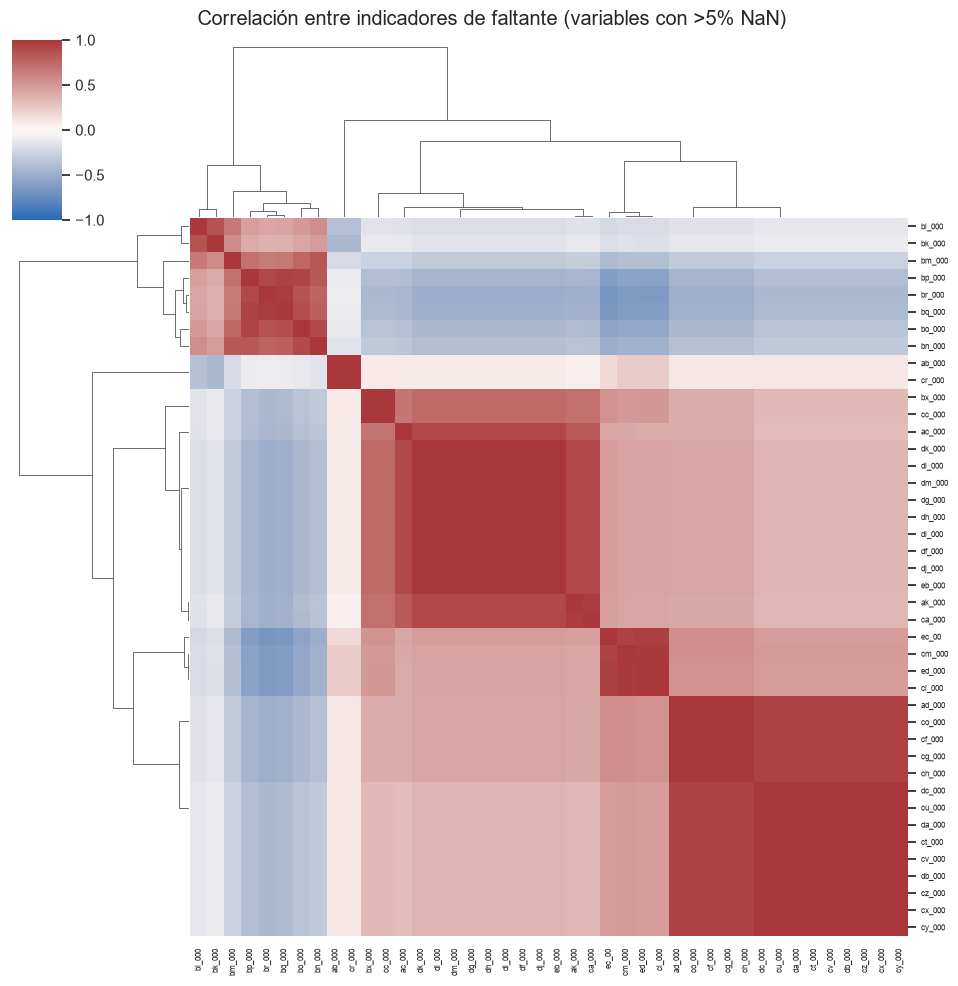

Pares de indicadores con corr > 0.9: 168 de 861


In [9]:
# ¿Los faltantes aparecen juntos? Correlación entre indicadores de NaN (variables con >5% faltante)
ind = X[miss[miss > 0.05].index].isna().astype(int)
c = ind.corr()
g = sns.clustermap(c, cmap="vlag", vmin=-1, vmax=1, figsize=(10, 10), xticklabels=True, yticklabels=True)
g.ax_heatmap.tick_params(labelsize=6)
g.fig.suptitle("Correlación entre indicadores de faltante (variables con >5% NaN)", y=1.01)
g.savefig(FIG / "01_corr_indicadores_faltantes.png", dpi=110, bbox_inches="tight"); plt.show()
upper = c.where(np.triu(np.ones(c.shape, bool), 1))
print(f"Pares de indicadores con corr > 0.9: {(upper > 0.9).sum().sum()} de {upper.notna().sum().sum()}")

,% faltante,tasa pos | NaN,tasa pos | presente,ratio
variable,,,,
di_000,0.067,0.131,0.009,15.387
dk_000,0.067,0.131,0.009,15.383
dj_000,0.067,0.131,0.009,15.383
eb_000,0.067,0.131,0.009,15.383
dg_000,0.067,0.131,0.009,15.379
df_000,0.067,0.131,0.009,15.379
dh_000,0.067,0.131,0.009,15.379
dl_000,0.067,0.131,0.009,15.379
dm_000,0.067,0.131,0.009,15.375


,% faltante,tasa pos | NaN,tasa pos | presente,ratio
variable,,,,
br_000,0.821,0.002,0.085,0.022
bq_000,0.812,0.002,0.081,0.022
bp_000,0.796,0.002,0.075,0.023
bo_000,0.772,0.002,0.067,0.025
bn_000,0.733,0.002,0.058,0.029


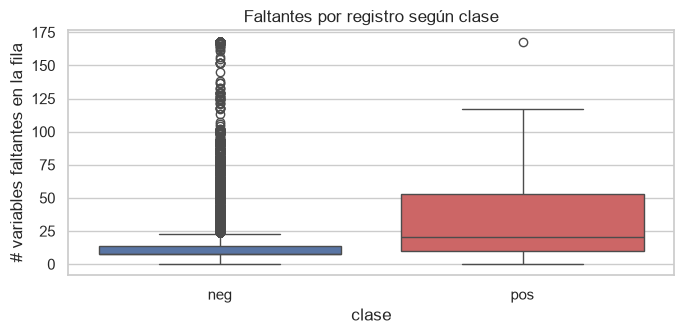

          count       mean        std  min   25%   50%   75%    max
target                                                             
0       59000.0  13.912915  15.822130  0.0  8.00   8.0  14.0  168.0
1        1000.0  29.153000  23.382822  0.0  9.75  20.5  53.0  168.0


In [10]:
# ¿El faltante es informativo? Tasa de falla APS cuando la variable falta vs cuando está presente
rows = []
for col in miss[miss > 0.01].index:
    na = X[col].isna()
    rows.append({"variable": col, "% faltante": na.mean(),
                 "tasa pos | NaN": y[na].mean(), "tasa pos | presente": y[~na].mean()})
inf = pd.DataFrame(rows).set_index("variable")
inf["ratio"] = inf["tasa pos | NaN"] / inf["tasa pos | presente"]
display(inf.sort_values("ratio", ascending=False).head(10).style.format("{:.3f}"))
display(inf.sort_values("ratio").head(5).style.format("{:.3f}"))

# Número de faltantes por fila según clase
n_na = X.isna().sum(axis=1)
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.boxplot(x=y.map({0: "neg", 1: "pos"}), y=n_na, ax=ax, palette=["#4C72B0", "#DD5555"])
ax.set(xlabel="clase", ylabel="# variables faltantes en la fila", title="Faltantes por registro según clase")
plt.tight_layout(); savefig("01_faltantes_por_fila"); plt.show()
print(n_na.groupby(y).describe())

**Hallazgos sobre faltantes**
- El **8,3 %** de las celdas está vacío y el **99 %** de los camiones tiene al menos un NaN, así que eliminar filas no es una opción.
- La mayoría de las variables (127 de 170) tiene ≤ 5 % de faltantes. **7 variables superan el 70 %** (`br_000` 82 %, `bq_000`, `bp_000`, `bo_000`, `ab_000`, `cr_000` 77 %, `bn_000` 73 %).
- Los faltantes **aparecen en bloques**: 168 pares de indicadores de NaN tienen correlación > 0,9. Esto sugiere que faltan grupos completos de sensores, por ejemplo los 10 bins de un histograma a la vez.
- **El faltante es informativo**:
  - Cuando falta el bloque `df_000…eb_000` (6,7 % de faltantes), la tasa de falla APS sube del **0,9 % al 13,1 %**, unas 15 veces más.
  - En las variables con > 70 % de NaN ocurre lo contrario: *estar presente* se asocia con más fallas (8,5 % frente a 0,2 %).
  - Los camiones con falla tienen en mediana **20,5 variables faltantes**, frente a **8** en los camiones sin falla.
- Conclusión: además de imputar, conviene **conservar indicadores de faltante**. Así el modelo puede aprovechar ese patrón.

## 4. Distribuciones y asimetría

Top 8 variables por AUC univariado:


,ci_000,ck_000,aa_000,bt_000,bj_000,ap_000,bb_000,dn_000
AUC,0.969,0.968,0.967,0.965,0.946,0.942,0.942,0.941


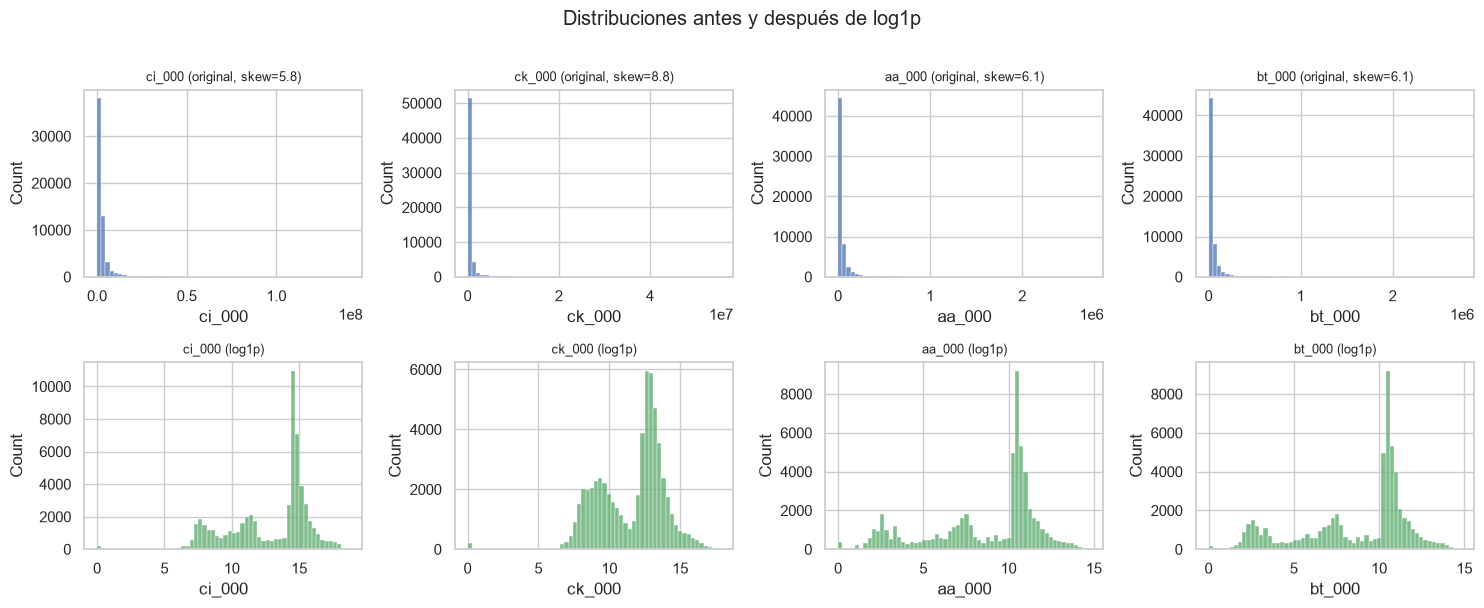

In [ ]:
# Poder discriminante univariado (AUC de cada variable sola, imputando mediana) — solo para explorar
from sklearn.metrics import roc_auc_score

Xm = X.fillna(X.median())
uni_auc = Xm.apply(lambda s: roc_auc_score(y, s)).rename("AUC")
uni_auc = (uni_auc - 0.5).abs().add(0.5).sort_values(ascending=False)
top = uni_auc.head(8).index.tolist()
print("Top 8 variables por AUC univariado:")
display(uni_auc.head(8).to_frame().T.round(3))

fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for i, col in enumerate(top[:4]):
    sns.histplot(X[col].dropna(), bins=60, ax=axes[0, i], color="#4C72B0")
    axes[0, i].set_title(f"{col} (original, skew={X[col].skew():.1f})", fontsize=9)
    sns.histplot(signed_log1p(X[col].dropna()), bins=60, ax=axes[1, i], color="#55A868")
    axes[1, i].set_title(f"{col} (log1p)", fontsize=9)
plt.suptitle("Distribuciones antes y después de log1p", y=1.01)
plt.tight_layout()
savefig("01_log_transform")
plt.show()

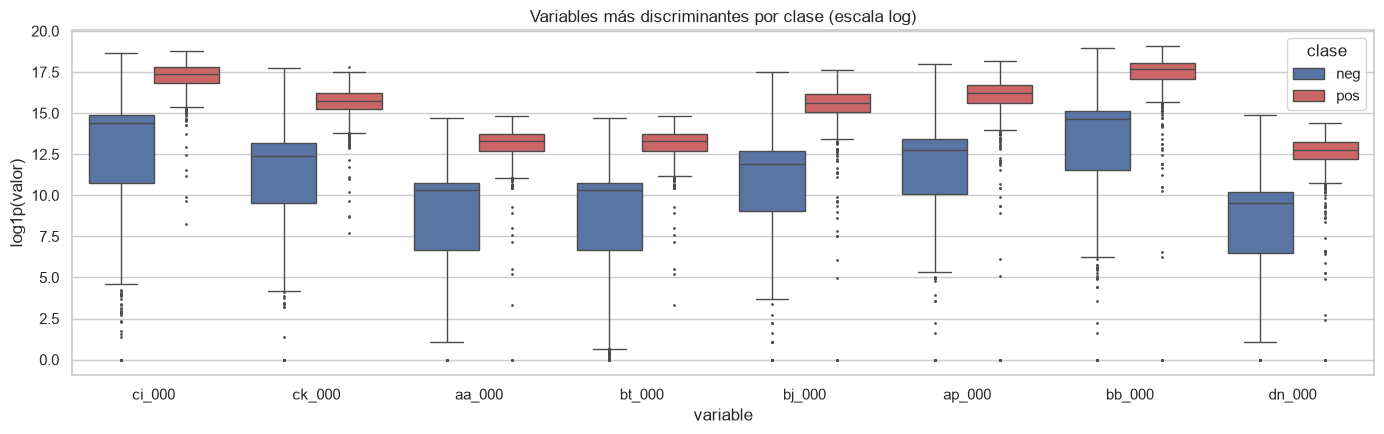

In [ ]:
long = (
    signed_log1p(X[top]).assign(clase=y.map({0: "neg", 1: "pos"})).melt(id_vars="clase")
)
fig, ax = plt.subplots(figsize=(14, 4.5))
sns.boxplot(
    data=long,
    x="variable",
    y="value",
    hue="clase",
    ax=ax,
    palette=["#4C72B0", "#DD5555"],
    fliersize=1,
)
ax.set(
    ylabel="log1p(valor)", title="Variables más discriminantes por clase (escala log)"
)
plt.tight_layout()
savefig("01_boxplots_top_variables")
plt.show()

## 5. Correlación y redundancia

Pares con |corr| > 0.95: 172 | > 0.9: 474 | > 0.8: 1250


|corr|
bv_000 cq_000   1.000
bu_000 cq_000   1.000
       bv_000   1.000
ah_000 bg_000   0.999
bb_000 cq_000   0.999
       bv_000   0.999
       bu_000   0.999
dq_000 dr_000   0.996
an_000 ao_000   0.995
cv_000 dc_000   0.993

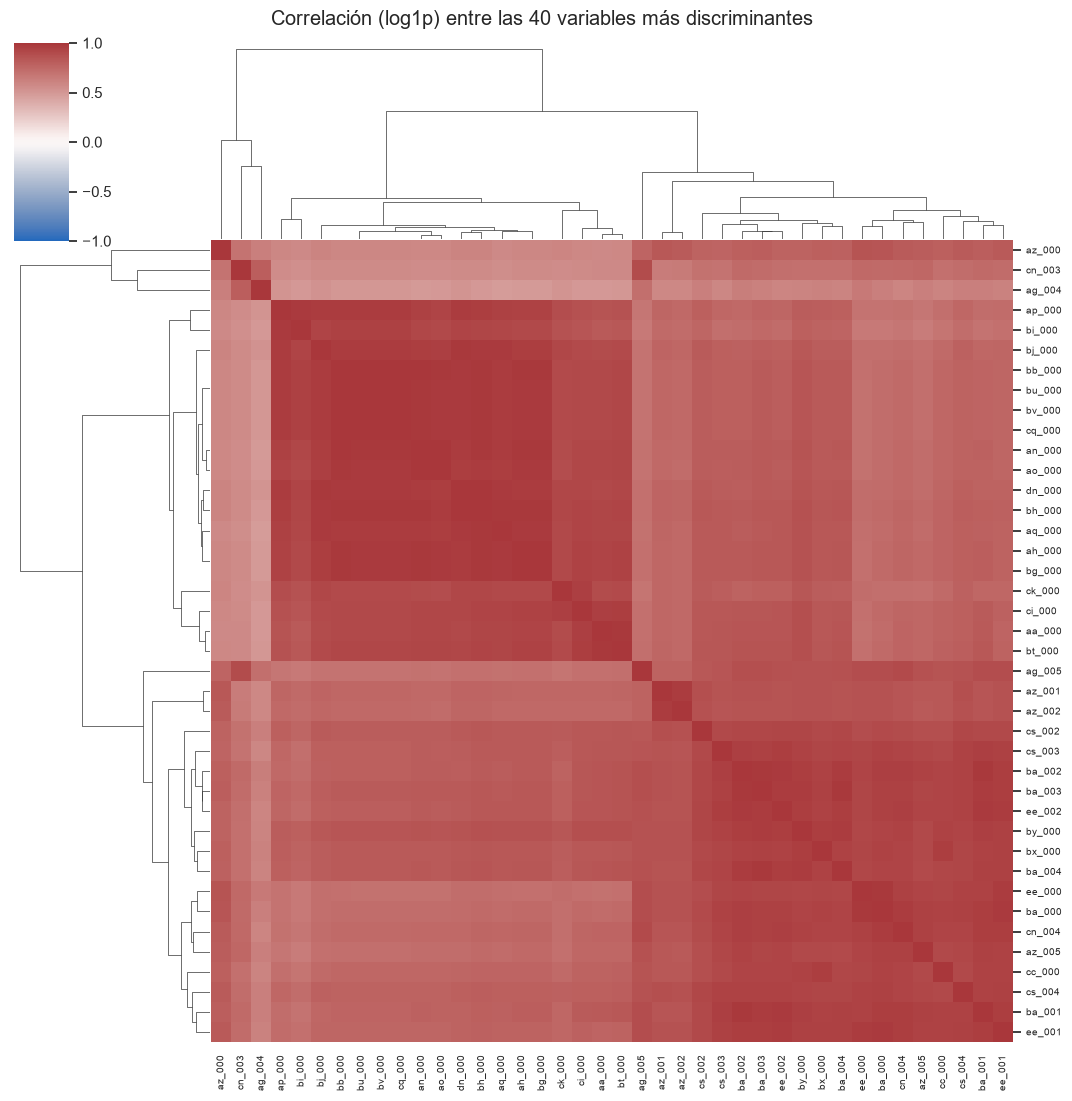

In [ ]:
corr = signed_log1p(Xm).corr()
upper = corr.abs().where(np.triu(np.ones(corr.shape, bool), 1))
pairs = upper.stack().sort_values(ascending=False)
print(
    f"Pares con |corr| > 0.95: {(pairs > 0.95).sum()} | > 0.9: {(pairs > 0.9).sum()} | > 0.8: {(pairs > 0.8).sum()}"
)
display(pairs.head(10).to_frame("|corr|").round(3))

sel = uni_auc.head(40).index
g = sns.clustermap(
    corr.loc[sel, sel],
    cmap="vlag",
    vmin=-1,
    vmax=1,
    figsize=(11, 11),
    xticklabels=True,
    yticklabels=True,
)
g.ax_heatmap.tick_params(labelsize=7)
g.fig.suptitle("Correlación (log1p) entre las 40 variables más discriminantes", y=1.01)
g.savefig(FIG / "01_correlacion_top40.png", dpi=110, bbox_inches="tight")
plt.show()

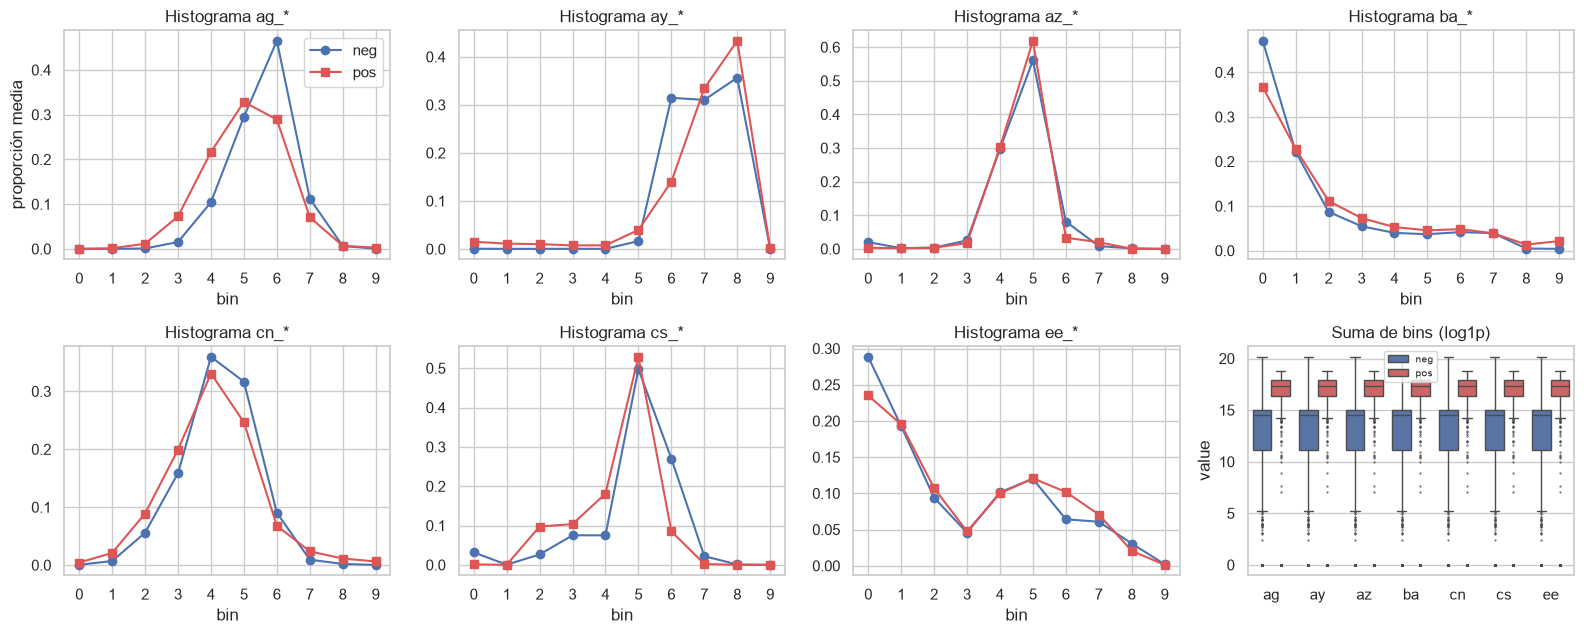

In [14]:
# Perfil de los 7 histogramas: distribución media normalizada de los bins por clase
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5), sharey=False)
for ax, (g_name, cols) in zip(axes.ravel(), groups.items()):
    H = X[cols].fillna(0)
    Hn = H.div(H.sum(axis=1).replace(0, np.nan), axis=0)
    prof = Hn.groupby(y).mean().T
    ax.plot(range(10), prof[0], "o-", label="neg", c="#4C72B0")
    ax.plot(range(10), prof[1], "s-", label="pos", c="#DD5555")
    ax.set_title(f"Histograma {g_name}_*"); ax.set_xticks(range(10)); ax.set_xlabel("bin")
axes[0, 0].legend(); axes[0, 0].set_ylabel("proporción media")
# Totales (suma de bins) por clase
tot = pd.DataFrame({g_name: X[cols].sum(axis=1, min_count=1) for g_name, cols in groups.items()})
ax = axes.ravel()[-1]
sns.boxplot(data=signed_log1p(tot).assign(c=y.map({0: "neg", 1: "pos"})).melt(id_vars="c"),
            x="variable", y="value", hue="c", ax=ax, palette=["#4C72B0", "#DD5555"], fliersize=0.5)
ax.set_title("Suma de bins (log1p)"); ax.set_xlabel(""); ax.legend(fontsize=7)
plt.tight_layout(); savefig("01_histogramas_por_clase"); plt.show()

**Hallazgos sobre distribuciones y redundancia**
- No hay valores negativos. Todas las variables son conteos o magnitudes ≥ 0, y **157 de 170 tienen asimetría > 5**, con colas de hasta 10⁹. La transformación `log1p` comprime esas colas y deja distribuciones mucho más manejables para modelos lineales y basados en distancias.
- Varias variables discriminan muy bien por sí solas: `ci_000`, `ck_000`, `aa_000` y `bt_000` tienen AUC univariado ≥ 0,96. En todas, los camiones con falla APS registran **valores más altos**.
- Hay **mucha redundancia**: 172 pares con |r| > 0,95 y 474 con |r| > 0,9. Algunas variables son casi copias, como `bu_000`, `bv_000`, `cq_000` y `ah_000`/`bg_000`. Esto justifica un filtro de correlación, sobre todo para la regresión logística.
- **Histogramas**:
  - En el 97,5 % de los camiones, los 7 histogramas tienen **exactamente la misma suma de bins**. Probablemente es el tiempo o contador de operación que se reparte entre los bins. Esa suma es **unas 15 veces mayor en mediana** en los camiones con falla APS (3,3·10⁷ frente a 2,1·10⁶), es decir, en los camiones más usados.
  - La *forma* del histograma también difiere: en `ag_*`, `cs_*` y `cn_*` los camiones con falla tienen más proporción en los bins intermedios (2–5) y menos en el bin 6.

## 6. Estrategias de imputación
Se comparan varias estrategias de imputación dentro de un `Pipeline`, de modo que el imputador **se ajusta solo con los folds de entrenamiento** de cada partición (sin fuga). El modelo de referencia es una regresión logística balanceada y la métrica es **PR-AUC** con validación cruzada estratificada de 5 folds.

KNN e Iterative son costosos (KNN crece de forma cuadrática con el número de filas), así que la comparación se hace sobre una **muestra estratificada de 15 000 filas** del train (conserva el 1,67 % de positivos). Todas las estrategias usan la misma muestra y los mismos folds para que la comparación sea justa.

In [15]:
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer

X_s, _, y_s, _ = train_test_split(X, y, train_size=15000, stratify=y, random_state=SEED)
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
lr = lambda: LogisticRegression(class_weight="balanced", max_iter=3000, C=0.1)

def pipe_with(imputer, scale_first=False):
    steps = [("drop", DropHighMissing(0.7))]
    if scale_first:  # KNN necesita distancias en escala comparable
        steps += [("log", FunctionTransformer(signed_log1p)), ("pre_scale", StandardScaler())]
    steps += [("impute", imputer)]
    if not scale_first:
        steps += [("log", FunctionTransformer(signed_log1p))]
    steps += [("scale", StandardScaler()), ("clf", lr())]
    return Pipeline(steps)

strategies = {
    "Mediana": pipe_with(SimpleImputer(strategy="median")),
    "Mediana + indicador NaN": pipe_with(SimpleImputer(strategy="median", add_indicator=True)),
    "Constante 0": pipe_with(SimpleImputer(strategy="constant", fill_value=0)),
    "KNN (k=5)": pipe_with(KNNImputer(n_neighbors=5), scale_first=True),
    "Iterative (BayesianRidge)": pipe_with(IterativeImputer(max_iter=5, n_nearest_features=20, random_state=SEED)),
}
rows = []
for name, p in strategies.items():
    t0 = time.time()
    r = cross_validate(p, X_s, y_s, cv=cv, scoring=["average_precision", "roc_auc", "recall"], n_jobs=-1)
    rows.append({"estrategia": name, "PR-AUC": r["test_average_precision"].mean(),
                 "PR-AUC std": r["test_average_precision"].std(), "ROC-AUC": r["test_roc_auc"].mean(),
                 "Recall@0.5": r["test_recall"].mean(), "tiempo (s)": time.time() - t0})
imp_res = pd.DataFrame(rows).set_index("estrategia").sort_values("PR-AUC", ascending=False)
imp_res.to_csv(RESULTS / "01_imputacion_cv.csv")
imp_res.style.format("{:.3f}").format("{:.1f}", subset=["tiempo (s)"])

,PR-AUC,PR-AUC std,ROC-AUC,Recall@0.5,tiempo (s)
estrategia,,,,,
Mediana,0.719,0.038,0.968,0.900,7.7
Mediana + indicador NaN,0.711,0.051,0.973,0.864,8.0
KNN (k=5),0.703,0.052,0.967,0.876,233.3
Constante 0,0.702,0.054,0.973,0.872,2.5
Iterative (BayesianRidge),0.690,0.061,0.971,0.852,35.8


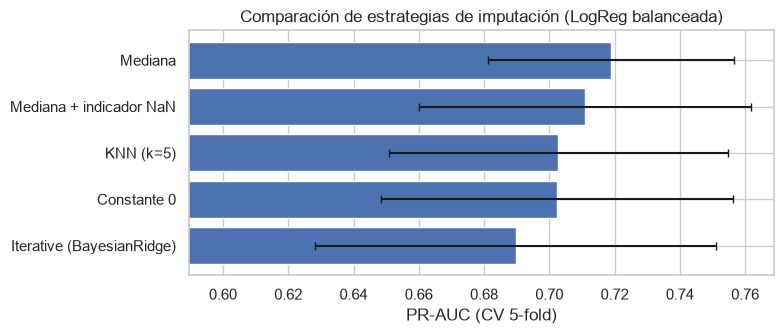

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(imp_res.index[::-1], imp_res["PR-AUC"][::-1], xerr=imp_res["PR-AUC std"][::-1], color="#4C72B0", capsize=3)
ax.set(xlabel="PR-AUC (CV 5-fold)", title="Comparación de estrategias de imputación (LogReg balanceada)")
ax.set_xlim(imp_res["PR-AUC"].min() - 0.1, min(1, imp_res["PR-AUC"].max() + 0.05))
plt.tight_layout(); savefig("01_comparacion_imputacion"); plt.show()

## 7. Selección de características
Se combinan cuatro filtros que no usan la variable objetivo (salvo el último, que solo es descriptivo):
1. **Umbral de faltantes**: se descartan las columnas con más del X % de NaN. Se prueba la sensibilidad a X.
2. **Varianza cero**: se descartan las constantes (`cd_000`).
3. **Filtro de correlación**: de cada par con |r| > 0,95 se conserva una variable.
4. **Información mutua** con la clase, calculada solo con el train para describir la relevancia (no se usa para filtrar dentro del pipeline).

In [ ]:
rows = []
for thr in [0.5, 0.7, 0.9, 1.0]:
    for corr_thr in [None, 0.95]:
        p = Pipeline([("prep", build_preprocessor(missing_threshold=thr, corr_threshold=corr_thr)), ("clf", lr())])
        r = cross_validate(p, X_s, y_s, cv=cv, scoring="average_precision", n_jobs=-1)
        n_feat = build_preprocessor(missing_threshold=thr, corr_threshold=corr_thr).fit_transform(X_s).shape[1]
        rows.append({"umbral faltantes": thr, "filtro corr": "0.95" if corr_thr else "no",
                     "# variables": n_feat, "PR-AUC": r["test_score"].mean(), "std": r["test_score"].std()})
sel_res = pd.DataFrame(rows)
sel_res.to_csv(RESULTS / "01_seleccion_cv.csv", index=False)
sel_res.style.format({"PR-AUC": "{:.3f}", "std": "{:.3f}"})

In [ ]:
# Pipeline por defecto aplicado al train completo: trazabilidad de variables
prep = build_preprocessor()
Z = prep.fit_transform(X)
s = prep.named_steps
n_drop = len(s["drop_missing"].dropped_)
n_after_imp = s["impute"].get_feature_names_out().shape[0]
n_after_var = s["variance"].get_feature_names_out().shape[0]
trace = pd.Series({
    "Variables originales": X.shape[1],
    f"Tras eliminar >70% NaN (−{n_drop})": X.shape[1] - n_drop,
    "Tras imputar + indicadores NaN": n_after_imp,
    "Tras eliminar varianza cero": n_after_var,
    f"Tras filtro de correlación (−{len(s['corr'].dropped_)})": Z.shape[1],
}, name="# columnas")
display(trace.to_frame())
print("Eliminadas por faltantes:", s["drop_missing"].dropped_)
print("Eliminadas por correlación:", s["corr"].dropped_)

,# columnas
Variables originales,170
Tras eliminar >70% NaN (−7),163
Tras imputar + indicadores NaN,325
Tras eliminar varianza cero,324
Tras filtro de correlación (−181),143


Eliminadas por faltantes: ['ab_000', 'bn_000', 'bo_000', 'bp_000', 'bq_000', 'br_000', 'cr_000']
Eliminadas por correlación: ['af_000', 'am_0', 'an_000', 'ao_000', 'aq_000', 'ay_002', 'az_002', 'ba_001', 'ba_002', 'ba_004', 'ba_005', 'bb_000', 'bg_000', 'bh_000', 'bi_000', 'bj_000', 'bt_000', 'bu_000', 'bv_000', 'by_000', 'cc_000', 'ci_000', 'cn_004', 'cn_005', 'cn_008', 'cq_000', 'cs_005', 'ct_000', 'dc_000', 'dm_000', 'dn_000', 'dp_000', 'dr_000', 'dt_000', 'dv_000', 'ee_000', 'ee_001', 'ee_002', 'ee_003', 'ee_004', 'missingindicator_af_000', 'missingindicator_ag_001', 'missingindicator_ag_002', 'missingindicator_ag_003', 'missingindicator_ag_004', 'missingindicator_ag_005', 'missingindicator_ag_006', 'missingindicator_ag_007', 'missingindicator_ag_008', 'missingindicator_ag_009', 'missingindicator_aj_000', 'missingindicator_am_0', 'missingindicator_an_000', 'missingindicator_ap_000', 'missingindicator_aq_000', 'missingindicator_ar_000', 'missingindicator_as_000', 'missingindicator_a

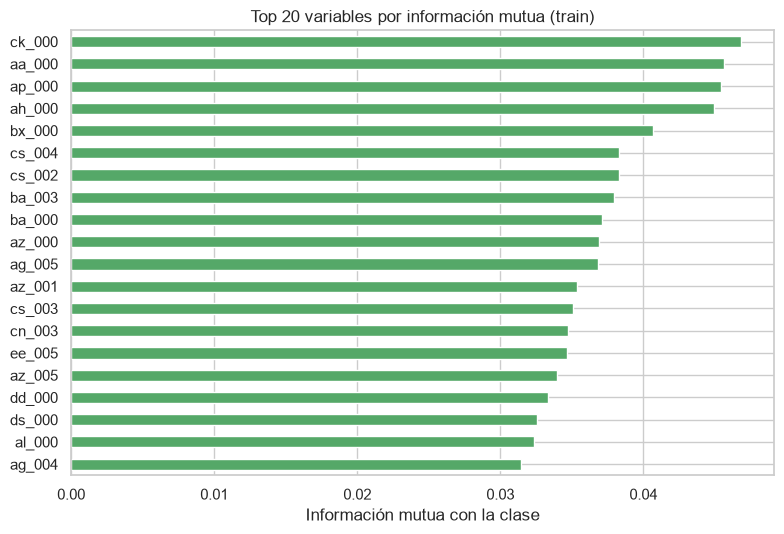

Variables con MI ≈ 0 (< 0.001): 20 de 143
Grupo de histograma en el top 20: ['cs_004', 'cs_002', 'ba_003', 'ba_000', 'az_000', 'ag_005', 'az_001', 'cs_003', 'cn_003', 'ee_005', 'az_005', 'ag_004']


In [ ]:
from sklearn.feature_selection import mutual_info_classif
mi = pd.Series(mutual_info_classif(Z, y, random_state=SEED, n_neighbors=5), index=Z.columns).sort_values(ascending=False)
mi.to_csv(RESULTS / "01_mutual_information.csv")
fig, ax = plt.subplots(figsize=(8, 5.5))
mi.head(20)[::-1].plot.barh(ax=ax, color="#55A868")
ax.set(xlabel="Información mutua con la clase", title="Top 20 variables por información mutua (train)")
plt.tight_layout(); savefig("01_mutual_information"); plt.show()
print(f"Variables con MI ≈ 0 (< 0.001): {(mi < 0.001).sum()} de {len(mi)}")
print("Grupo de histograma en el top 20:", [c for c in mi.head(20).index if c[:2] in groups])

## 8. Reducción de dimensionalidad (visualización)
PCA se ajusta sobre el train ya preprocesado (imputado, log, escalado). t-SNE se ejecuta sobre una submuestra de **4 000 negativos y los 1 000 positivos**. Se sobrerrepresentan los positivos a propósito para que se vean, así que la proporción visual no es la real. La clase se usa **solo para colorear**.

Componentes para 90% varianza: 53 | 95%: 73 | (de 143 variables)
PC1+PC2 explican 36.6%


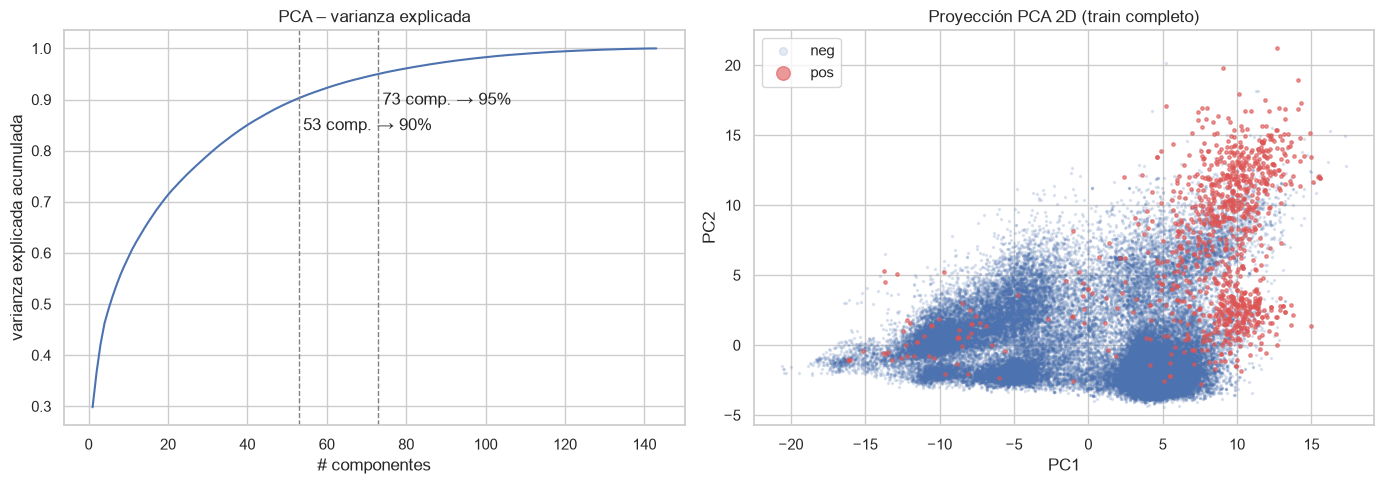

In [ ]:
from sklearn.decomposition import PCA
pca = PCA(random_state=SEED).fit(Z)
cum = np.cumsum(pca.explained_variance_ratio_)
k90, k95 = np.searchsorted(cum, 0.90) + 1, np.searchsorted(cum, 0.95) + 1
print(f"Componentes para 90% varianza: {k90} | 95%: {k95} | (de {Z.shape[1]} variables)")
print(f"PC1+PC2 explican {cum[1]:.1%}")

P = pca.transform(Z)[:, :2]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(range(1, len(cum) + 1), cum, c="#4C72B0")
for k, lvl in [(k90, .9), (k95, .95)]:
    axes[0].axvline(k, ls="--", c="grey", lw=1); axes[0].text(k + 1, lvl - 0.06, f"{k} comp. → {lvl:.0%}")
axes[0].set(xlabel="# componentes", ylabel="varianza explicada acumulada", title="PCA – varianza explicada")
neg, pos = (y == 0).values, (y == 1).values
axes[1].scatter(P[neg, 0], P[neg, 1], s=2, alpha=0.15, c="#4C72B0", label="neg")
axes[1].scatter(P[pos, 0], P[pos, 1], s=6, alpha=0.6, c="#DD5555", label="pos")
axes[1].set(xlabel="PC1", ylabel="PC2", title="Proyección PCA 2D (train completo)"); axes[1].legend(markerscale=4)
plt.tight_layout(); savefig("01_pca"); plt.show()

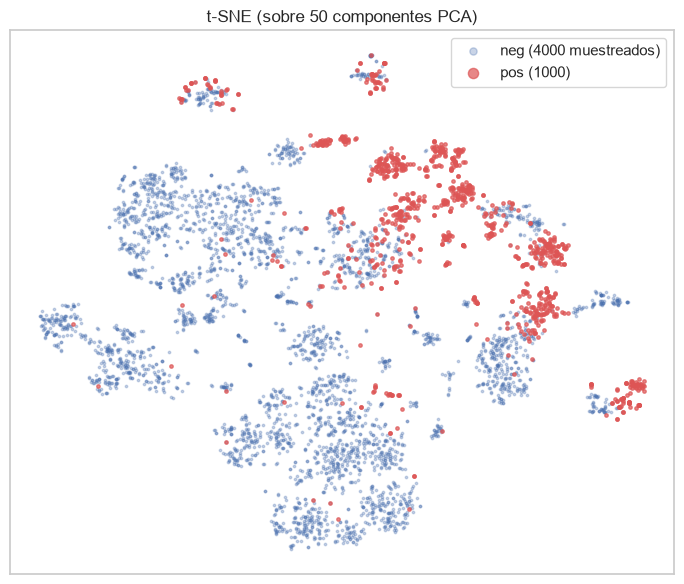

In [ ]:
from sklearn.manifold import TSNE
rng = np.random.default_rng(SEED)
idx = np.r_[rng.choice(np.where(neg)[0], 4000, replace=False), np.where(pos)[0]]
Z50 = pca.transform(Z.iloc[idx])[:, :50]
T = TSNE(n_components=2, perplexity=40, init="pca", random_state=SEED).fit_transform(Z50)
lab = y.iloc[idx].values
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(T[lab == 0, 0], T[lab == 0, 1], s=3, alpha=0.3, c="#4C72B0", label="neg (4000 muestreados)")
ax.scatter(T[lab == 1, 0], T[lab == 1, 1], s=6, alpha=0.7, c="#DD5555", label="pos (1000)")
ax.set_title("t-SNE (sobre 50 componentes PCA)"); ax.legend(markerscale=3); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); savefig("01_tsne"); plt.show()

## 9. Conclusiones del EDA y decisiones de preprocesamiento
1. **Estructura:** 60 000 camiones (train) y 16 000 (test) con 170 variables numéricas anónimas, 70 de ellas en 7 histogramas. Desbalance severo: **1,67 % de fallas en train** y 2,34 % en test. La accuracy no sirve y se usarán Recall, Precision, F1, PR-AUC y el costo `10·FP + 500·FN`.
2. **Faltantes:** son frecuentes (8,3 % de las celdas), aparecen en bloques y **son informativos**. Se eliminan las 7 columnas con más del 70 % de NaN y en el resto se imputa la **mediana**, que es robusta frente a las colas largas, junto con **indicadores de faltante**.
3. **Imputación:**
   - Con la regresión logística, la mediana obtuvo la mejor PR-AUC (0,719). Mediana + indicador obtuvo 0,711, KNN 0,703 y Iterative 0,690. Pero **todas las diferencias están dentro de una desviación estándar** (≈ 0,04–0,06).
   - KNN tardó unas 16 veces más (346 s frente a 22 s) sin mejorar el resultado, e Iterative fue la peor opción.
   - Se elige **mediana + indicador**: es igual de buena, es simple y es barata, y además conserva la señal de faltante que encontró el EDA, que los modelos de árboles pueden aprovechar mejor que la logística.
4. **Selección de variables:**
   - El umbral de faltantes (50–100 %) y el filtro de correlación mueven la PR-AUC menos de 0,01, también dentro del ruido.
   - El filtro de correlación **reduce las columnas de 324 a 143**, sobre todo indicadores de NaN duplicados, sin perder desempeño. Eso abarata los modelos y facilita el análisis de agrupamiento.
   - La información mutua confirma que 12 de las 20 variables más informativas pertenecen a histogramas (`cs`, `ba`, `az`, `ag`, `cn`, `ee`).
5. **Dimensionalidad:**
   - PCA necesita **53 componentes para el 90 %** de la varianza (73 para el 95 %). La información está repartida y PC1+PC2 solo explican el 36,6 %.
   - Aun así, en PC1–PC2 las fallas se concentran en una región de valores altos, y en t-SNE forman **varios grupos compactos**. Esto sugiere que hay **más de un perfil de falla** y es una pista para el componente no supervisado.

### Configuración elegida para `build_preprocessor()` (la usan los notebooks 02 y 03)
```python
build_preprocessor(
    missing_threshold=0.7,   # elimina 7 columnas con >70% NaN
    add_indicators=True,     # mediana + indicador de faltante
    log_transform=True,      # log1p (157/170 variables muy asimétricas)
    corr_threshold=0.95,     # 324 -> 143 columnas
    scale=True,              # StandardScaler (necesario para LogReg y clustering)
)
```

> Todas las transformaciones viven en `src/preprocessing.py` y se ajustan **solo con los datos de entrenamiento** dentro de un `Pipeline`, lo que evita fugas en la validación cruzada y en el test.